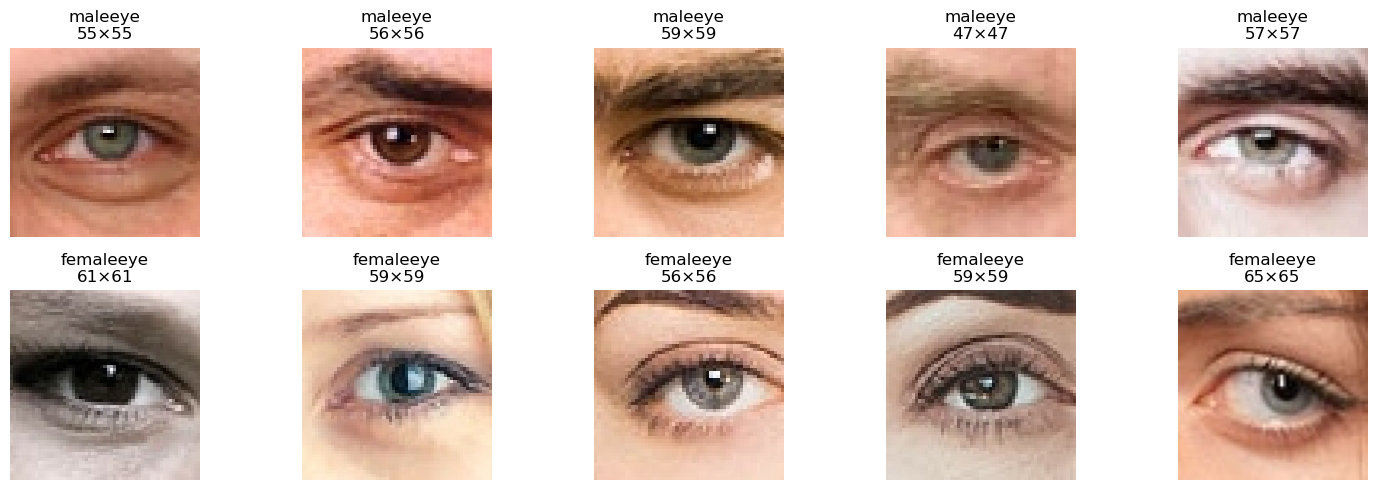

In [1]:
# VISUALIZING SAMPLES OF IMAGES, THEIR DIMENSIONS AND NUMBERS:
#--------------------------------------------------------------

import os
import matplotlib.pyplot as plt
import random
from PIL import Image

base_dir = "human_eyes_dataset"

# A function to plot random samples of the images
def plot_samples(class_names=['maleeyes', 'femaleeyes'], n=5): 
    # classnames must match folder names for each class || n is the number of images to show per class.
    figure, subplots = plt.subplots(2, n, figsize=(15, 5))
    for i, cls in enumerate(class_names):
        all_images = os.listdir(os.path.join(base_dir, cls))
        for j in range (n):
            img_path = os.path.join(base_dir, cls, random.choice(all_images))
            img = Image.open(img_path)
            subplots[i, j].imshow(img)
            subplots[i, j].axis('off')
            subplots[i, j].set_title(f"{cls[:-1]}\n{img.size[0]}×{img.size[1]}")
    plt.tight_layout()
    plt.show()

plot_samples()

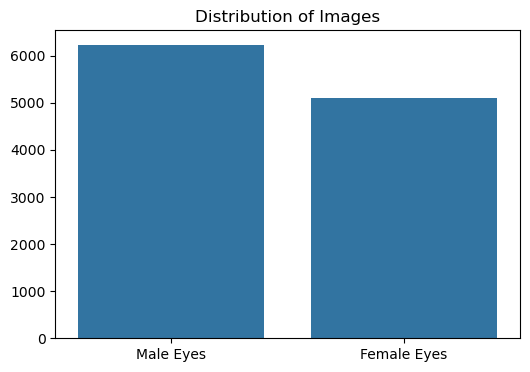

In [2]:
import seaborn as sns

# plotting the distribution of each class
class_names = ['maleeyes', 'femaleeyes']
class_counts = {}
for cls in class_names:
    # counting the number of images in each class name folder
    class_counts[cls]=len(os.listdir(os.path.join(base_dir, cls)))

plt.figure(figsize=(6,4))
barplot = sns.barplot(x=list(class_counts.keys()), y=list(class_counts.values()))
barplot.set_xticks([0, 1])
barplot.set_xticklabels(['Male Eyes', 'Female Eyes'])
plt.title('Distribution of Images')
plt.show()

In [3]:
# NORMALIZING THE DATASET
# -----------------------

from tensorflow.keras.preprocessing.image import ImageDataGenerator

image_size = (128, 128) # Resized image dimensions
batch_size = 32

# And now comes the ImageDataGenerator, a keras preprocessing image class that do a lot of stuff, but we'll just use it for :
datagen = ImageDataGenerator(
    rescale = 1/255, # Normalizing pixels values to fall in the range of [0, 1]
    validation_split=0.2, # The percentage of the validation images from the available images in the dataset
    # We can also specify how much an image should be rotated, zoomed, ... but ... well, who cares at my level
    rotation_range=20, # Added it based on advice from someone after I saw the horrible results of my model... :)
    horizontal_flip=True, # Also based on advice after intelligently deciding to train the model with a 200 image dataset per class :)
    width_shift_range=0.2,
    zoom_range=0.2
)

# SPLITTING DATA INTO TRAIN AND VALIDATION (TEST IS SPLITTED MANUALLY)
# --------------------------------------------------------------------

# Training subset generation
train_gen = datagen.flow_from_directory(
    base_dir, # root directory
    target_size = image_size, # Traget dimensions of resizing
    batch_size = batch_size, # number of images processed together
    class_mode = 'binary', # binary classification mode
    shuffle=True, # Shuffling data during training
    subset = 'training' # Based on the validation_split defined above, this subset will contain 80% of the images.
)

# validation subset generation
val_gen = datagen.flow_from_directory(
    base_dir, # root directory
    target_size = image_size,
    batch_size = batch_size,
    class_mode = 'binary', 
    shuffle=False,
    subset = 'validation' 
)

# BUILDING THE CNN ARCHITECTURE:
# ------------------------------

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout, GlobalAveragePooling2D, BatchNormalization
#from tensorflow.keras.regularizers import l2

model = Sequential([
        
        # Feature extraction
        Conv2D(32, (3,3), activation='relu', input_shape=(128, 128, 3), padding='valid'),
        BatchNormalization(), 
        MaxPooling2D((2,2)),
        
        Conv2D(64, (3,3), activation='relu', padding='valid'),
        BatchNormalization(),
        MaxPooling2D((2,2)),
        
        Conv2D(128, (3,3), activation='relu', padding='valid'),
        BatchNormalization(),
        MaxPooling2D((2,2)),
        
        Conv2D(128, (3,3), activation='relu', padding='valid'),
        BatchNormalization(),
        MaxPooling2D((2,2)),
        
        # Classifier
        Flatten(),
        Dense(512, activation='relu'),
        Dropout(0.5),
        Dense(1, activation='sigmoid')

])

# Let's see the model summary now
print("\n=============== Model Summary =================")
model.summary()

print("Train samples:", train_gen.samples)
print("Train labels distribution:", train_gen.classes.sum()) # counts of class '1'

print("Val samples:", val_gen.samples)
print("Val labels distribution:", val_gen.classes.sum())

Found 9072 images belonging to 2 classes.
Found 2268 images belonging to 2 classes.

=============== Model Summary =================
Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 126, 126, 32)      896       
                                                                 
 batch_normalization (BatchN  (None, 126, 126, 32)     128       
 ormalization)                                                   
                                                                 
 max_pooling2d (MaxPooling2D  (None, 63, 63, 32)       0         
 )                                                               
                                                                 
 conv2d_1 (Conv2D)           (None, 61, 61, 64)        18496     
                                                                 
 batch_normalization_1 (Batc  (None, 61, 61, 64)       

In [4]:
# CNN architecture visualization
from tensorflow.keras.utils import plot_model
plot_model(model, show_shapes=True)

You must install pydot (`pip install pydot`) and install graphviz (see instructions at https://graphviz.gitlab.io/download/) for plot_model to work.


In [5]:
# TRAINING THE MODEL
# ------------------

from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.optimizers import Adam

model.compile(optimizer=Adam(learning_rate=1e-4), loss='binary_crossentropy', metrics=['accuracy'])

early_stopping = EarlyStopping(
    monitor = 'val_loss',
    patience = 5,
    restore_best_weights = True
)

history = model.fit(train_gen, validation_data=val_gen, epochs=50, callbacks = [early_stopping])

model.save("male_female_eye_model.h5")

Epoch 1/50
284/284 [==============================] - 80s 251ms/step - loss: 0.6775 - accuracy: 0.6919 - val_loss: 1.2439 - val_accuracy: 0.5494
Epoch 2/50
284/284 [==============================] - 63s 223ms/step - loss: 0.4744 - accuracy: 0.7746 - val_loss: 0.6516 - val_accuracy: 0.7063
Epoch 3/50
284/284 [==============================] - 65s 229ms/step - loss: 0.4075 - accuracy: 0.8157 - val_loss: 0.3787 - val_accuracy: 0.8289
Epoch 4/50
284/284 [==============================] - 60s 211ms/step - loss: 0.3666 - accuracy: 0.8385 - val_loss: 0.3278 - val_accuracy: 0.8541
Epoch 5/50
284/284 [==============================] - 61s 215ms/step - loss: 0.3309 - accuracy: 0.8576 - val_loss: 0.3317 - val_accuracy: 0.8536
Epoch 6/50
284/284 [==============================] - 63s 220ms/step - loss: 0.3111 - accuracy: 0.8695 - val_loss: 0.2799 - val_accuracy: 0.8774
Epoch 7/50
284/284 [==============================] - 61s 214ms/step - loss: 0.2840 - accuracy: 0.8783 - val_loss: 0.2912 - val_ac

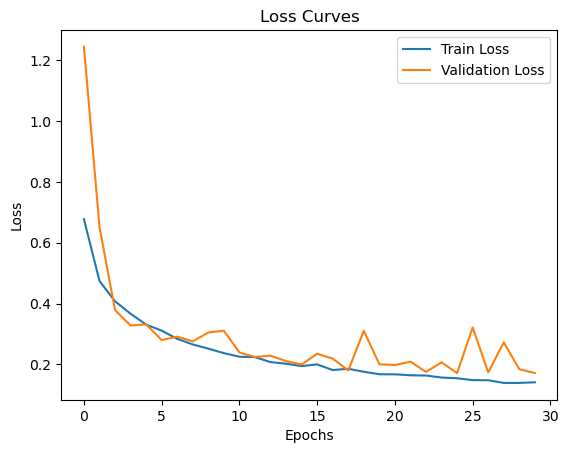

In [6]:
# Plotting loss curves of the trained model
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Loss Curves')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

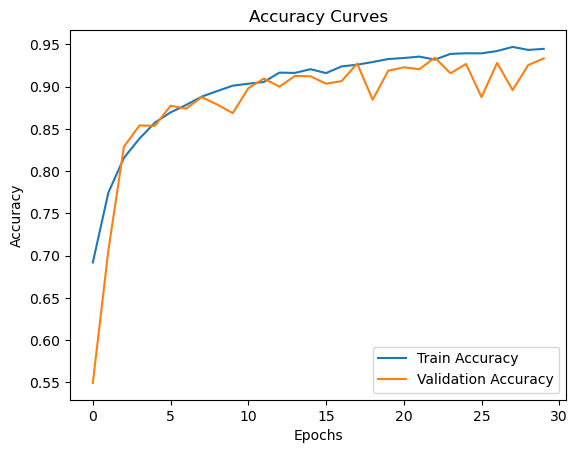

In [7]:
# Plotting the validation curves of the trained model
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Accuracy Curves')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

Found 185 images belonging to 2 classes.
6/6 [==============================] - 1s 91ms/step


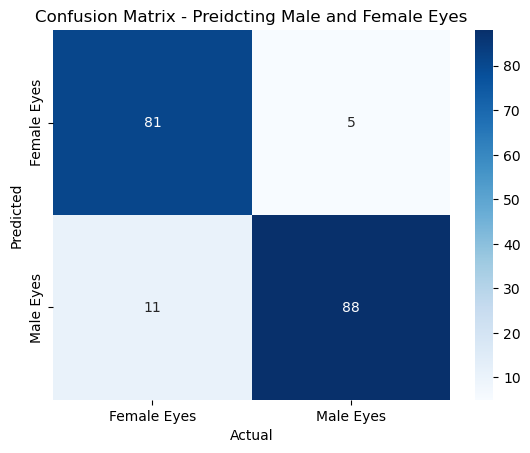

In [8]:
# TEST TIME:
# ----------

import pandas as pd

# Initializing the test data generator
test_datagen = ImageDataGenerator(rescale=1./255)

# Generating the test set -- well, not really generating except that pixel values are between 1 and 0
test_generator = test_datagen.flow_from_directory(
    'human_eyes_test',
    target_size = image_size,
    batch_size = batch_size,
    class_mode = 'binary',
    shuffle = False
)

# predict class probability for each image
pred_prob_y_test = model.predict(test_generator)

# convert probabilities to 1 or 0 based on if they are greater or less than 0.5 to obtain the class labels
pred_y_test = (pred_prob_y_test > 0.5).astype(int).flatten()

# Getting the actual classification from the test_generator
y_test = test_generator.classes

from sklearn.metrics import confusion_matrix

# And now seeing how much our model is good through the confusion matrix... hopefully i didn't mess it up :)
cm = confusion_matrix(pred_y_test, y_test)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Female Eyes', 'Male Eyes'], yticklabels=['Female Eyes', 'Male Eyes'])
plt.xlabel("Actual")
plt.ylabel("Predicted")
plt.title("Confusion Matrix - Preidcting Male and Female Eyes")
plt.show()